### The paper:

Sago et al. (2018): High-throughput in vivo screen of functional mRNA
delivery identifies nanoparticles for endothelial cell
gene editing. https://www.pnas.org/doi/pdf/10.1073/pnas.1811276115

### The model:

 The researchers measured the fraction of cells that turned RFP+ at three different doses of Cre mRNA (10, 100, 1000 ng) delivered by L2K, a specific formulation of a lipid nanoparticle (LNP). They did this to show that their reporter system responds to dose, and to find a dose range where differences between LNPs could still be told apart. So, they needed to find a dose range that was high enough that a large proportion of cells were RFP+, but not high enough that the system is "saturated".

 They found that the RFP+ fraction rose with dose and leveled off (became saturated) at over 80%.

 We propose that this saturation happens because each cell either gets at least one working mRNA copy or it doesn't. If a cell gets at least one copy, it turns red (RFP+). If it gets zero, it stays dark. At low doses, most cells get zero copies by chance, leading to a low % RFP+. As dose rises, each cell's odds of getting at least one copy climbs quickly at first, then plateaus towards a high probability.

 We model the number of copies a cell gets as a Poisson random variable - where each event (an mRNa copy ending up in a particular cell) is random,  independent across copies, and individually unlikely to occur.

 Z = number of mRNA copies a cell receives (our random variable)

 λ = k * dose (the average number of copies per cell, which depends on k (1/ng) and dose (ng)).
 
 Z ~ Poisson(λ)

 The measurement: a cell is RFP+ if Z >= 1.
 
 We can derive the measurement from the Poisson probability mass function:
 $$P(Z = n) = \frac{\lambda^n e^{-\lambda}}{n!}$$

 The probability for n = 0 (the cell receives Z = 0 copies, and thus the cell is RFP-):
 $$P(Z = 0) = \frac{\lambda^0 e^{-\lambda}}{0!}$$
 $$P(Z = 0) = \frac{1 e^{-\lambda}}{1}$$
 $$P(Z = 0) = e^{-\lambda}$$

 Then getting to P(RFP+):

 A cell is RFP+ if it receives at least one copy. Z >=1 is the complement of Z = 0, so:
 $$P(Z \ge 1) = 1 - P(Z = 0) = 1 - e^{-\lambda} = 1 - e^{-kD}$$

 Our assumptions using this model are:
 - A single functional copy of Cre mRNA triggers the RFP+ outcome. A cell taking up additional functional copies does not change the outcome.
 - The expected number of copies per cell, Z, scales linearly with dose.
 - All cells are identical and independent.
 - the delivery rate, k, is constant across the whole experiment, as the same delivery vehicle is used for each dose (in this specific experiment we are trying to model - later in the paper the researchers describe different LNPs and thus varying k values would be more appropriate.)



(0.0, 100.0)

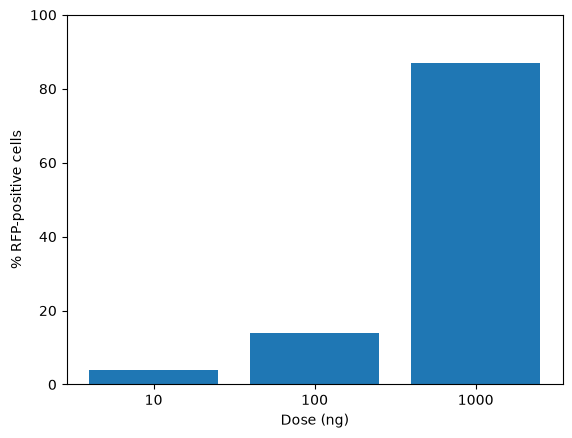

In [115]:
import math
import matplotlib.pyplot as plt

# The data, as estimated from Fig. 1G, Sago et al. 2018
dose = [10, 100, 1000] # in ng
pct_RFP_pos = [4, 14, 87] # % RFP+
observed_fractions = [p / 100 for p in pct_RFP_pos]

plt.bar([str(d) for d in dose], pct_RFP_pos)
plt.xlabel("Dose (ng)")
plt.ylabel("% RFP-positive cells")
plt.ylim(0, 100)

### Running it forwards (simulating):

To simulate the results, simulating a full Poisson count per cell is not necessary. Instead, we can just simulate whether a cell got zero copies (RFP-) or at least one (RFP+).

RFP- should happen with probability e^(−λ) (the Poisson chance of zero copies).

RFP+ should happen with probability 1 - e^(−λ).

To simulate this, we can draw one random number from the interval \[0, 1\), where every value in that range is equally likely. We then split that interval into two pieces, where each piece's length matches the probability of one outcome:

```
0              e^(-λ)                                  1
|-----------------|------------------------------------|
      RFP-        |                RFP+                 
  length = e^(-λ) |         length = 1 - e^(-λ)         
```

If a random number drawn, r, is less than e^(−λ), the cell is RFP-. Otherwise, the cell is RFP+.

In [117]:
A_LCG = 1664525
C_LCG = 1013904223
M_LCG = 2 ** 32

def lcg(state, a, c, m):
    """The next state of a linear congruential generator: s_{i+1} = (a * s_i + c) mod m."""
    return (a * state + c) % m

def uniforms(k, seed):
    """A list of k numbers on [0, 1): the generator run k times from the seed, each state divided by m."""
    out = [0.0] * k
    state = seed
    for i in range(k):
        state = lcg(state, A_LCG, C_LCG, M_LCG)
        out[i] = state / M_LCG
    return out

def p_model(k, dose):
    """Analytical probability that a cell is RFP+ at dose, for rate k."""
    """Takes k and the independent variable, dose and returns P(RFP+): 1 - e^(−λ) """
    return -math.expm1(-k * dose) # uses the negative of math.expm1 rather than 1 - math.exp to reduce computing errors that might arise with small lambda

def simulate(k, dose, n_cells=10000, seed=737):
    """Instead of simulating the actual Poisson counts, simulate the simplified version:
    either RFP-positive or RFP-negative based on a threshold."""
    probability_zero = math.exp(-k * dose)
    pos_count = 0
    draws = uniforms(n_cells, seed)
    for r in draws:
        if r >= probability_zero:
            pos_count += 1
    return pos_count / n_cells  # return the fraction of RFP+ cells

test_k = 0.0006
test_dose = 100

modeled = p_model(test_k, test_dose)
simulated = simulate(test_k, test_dose, n_cells = 10000, seed = 737)

# A small difference here implies that the simulate() function follows the model well
print("Using the test values:")
print(f"exact fraction from the model:          {modeled:.4f}")
print(f"simulated fraction from random draws:   {simulated:.4f}")
print(f"difference:                             {abs(modeled - simulated):.4f}")


Using the test values:
exact fraction from the model:          0.0582
simulated fraction from random draws:   0.0570
difference:                             0.0012


### Running it backwards (scoring):

We now see that the simulated values follow the model. However, the model does not perfectly fit the data - the fraction of RFP+ cells should be around 0.14 (14% RFP+) for a dose of 100 ng. Therefore, we must estimate the parameter k based off the paper's results.

The data are visual estimates of the bar heights in Fig. 1G of Sago et al.(2018), with doses of 10, 100, and 1000 ng resulting in 4, 14, and 87% RFP+, respectively.

First, we write a function to score a candidate k using the sum of squared errors (we can't use NLL here, as it would require cell counts):

In [118]:
def score(k, fractions):
    total = 0.0
    for i in range(len(dose)): # 3 doses: 10, 100, 1000 ng
        gap = p_model(k, dose[i]) - fractions[i]
        total += gap ** 2
    return total

Then, we create a range of candidates that k could be.

From the data, 
p(RFP+) = 1 − e^(−k·dose). We can solve for k and find:

1 - p(RFP+) = e^(−k·dose)

ln(1 - p) = -k * dose

→ k = −ln(1 − p) / dose

We can get a rough idea of k by inverting the model for each observed data point. 

When dose is 10, observed fraction = 0.04:  
k = -ln(1-0.04) / 10 ≈ 0.0041

When dose is 100, observed fraction = 0.14:    
k = −ln(1-0.14) / 100 ≈ 0.0015

When dose is 1000, observed fraction = 0.87:  
k = −ln(1-0.87) / 1000 ≈ 0.0020

We estimate that the most optimal k value will fall within a range of 0.001-0.0045.

In [119]:
M = 351
candidates = [0.0] * M
# a list of 351 candidates from 0.001-0.0045 with a step of 0.00001, without floating point rounding errors
for j in range(M): 
    candidates[j] = (100 + j) / 100000

scores = [0.0] * M
for j in range(M):
    scores[j] = score(candidates[j], observed_fractions)


The candidate k with the lowest score (k_hat) means that the model's curve is closer to the data. To find k_hat, find the position of the minimum score:

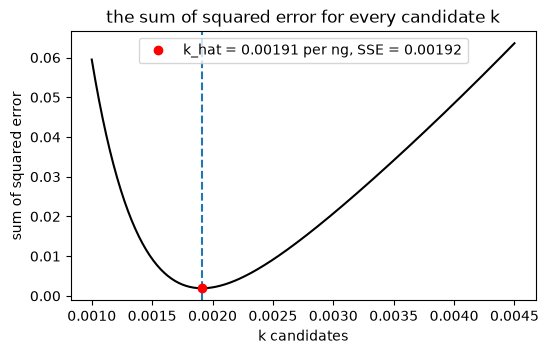

In [126]:
def position_of_min(values):
    """The index of the smallest entry"""
    best = 0
    for j in range(len(values)):
      if values[j] < values[best]:
        best = j
    return best

k_hat = candidates[position_of_min(scores)]
best_score = scores[position_of_min(scores)]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(candidates, scores, color="black")
ax.axvline(k_hat, ls="--")
ax.plot([k_hat], [best_score], "o", color="red", label=f"k_hat = {k_hat:.5f} per ng, SSE = {best_score:.5f}")
ax.set_xlabel("k candidates")
ax.set_ylabel("sum of squared error")
ax.set_title("the sum of squared error for every candidate k")
ax.legend()
plt.show()


The fitted k is 0.00191 per ng, with a sum of squared error of 0.00192.

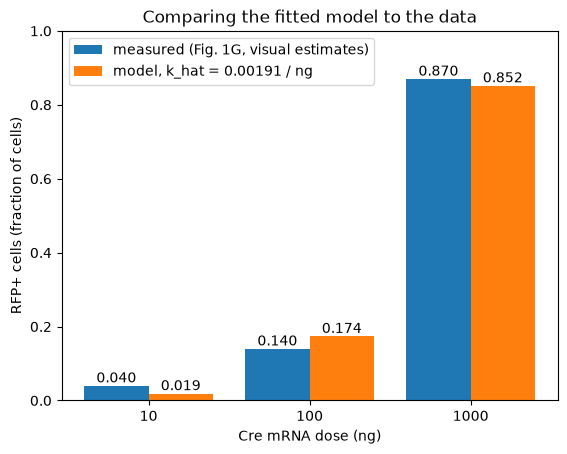

In [129]:
positions = [0, 1, 2]
obs_x = [0.0] * len(dose)
model_x = [0.0] * len(dose)
model_fractions = [0.0] * len(dose)
for i in range(len(dose)):
    obs_x[i] = positions[i] - 0.2            # measured bar sits left of the tick
    model_x[i] = positions[i] + 0.2          # model bar sits right of the tick
    model_fractions[i] = p_model(k_hat, dose[i]) # finding the estimates from the model with the fitted k

obs_bars = plt.bar(obs_x, observed_fractions, width=0.4, label="measured (Fig. 1G, visual estimates)")
model_bars = plt.bar(model_x, model_fractions, width=0.4, label=f"model, k_hat = {k_hat:.5f} / ng")
plt.bar_label(obs_bars, fmt="%.3f")          # value on top of each measured bar
plt.bar_label(model_bars, fmt="%.3f")        # value on top of each model bar
plt.xticks(positions, ["10", "100", "1000"])
plt.xlabel("Cre mRNA dose (ng)")
plt.ylabel("RFP+ cells (fraction of cells)")
plt.title("Comparing the fitted model to the data")
plt.ylim(0, 1)
plt.legend()
plt.show()

### Uncertainty:

The sweep above gave one best value of k. To see how much it depends on the data, we shift each observed fraction by a random amount of up to ±0.03 (3%) and refit 300 times. The size of the shift is assumed. It stands in for the error from reading the bars visually (in lieu of real data) and for the scatter between replicate wells. The spread of the refitted k shows how sensitive the estimate is to the data. The number of refits (300) was chosen to provide a stable interval with minimal computing power.

In [111]:
def fit_k(fractions):
    """Run the same sweep as before, on any list of fractions."""
    scores_i = [0.0] * M
    for j in range(M):
        scores_i[j] = score(candidates[j], fractions)
    return candidates[position_of_min(scores_i)]

n_repeats = 300
error = 0.03
draws = uniforms(n_repeats * 3, 737) # creates a list corresponding to one random number per dose per repeat

k_values = [0.0] * n_repeats
for r in range(n_repeats):
    shifted = [0.0] * len(dose)
    for i in range(len(dose)):
        # shifts each dose's "observed fraction" by a random number between -0.03 and +0.03
        shifted[i] = observed_fractions[i] + error * (2 * draws[3 * r + i] - 1)
    k_values[r] = fit_k(shifted) # runs the sweep on the altered data, stores the best k in position r

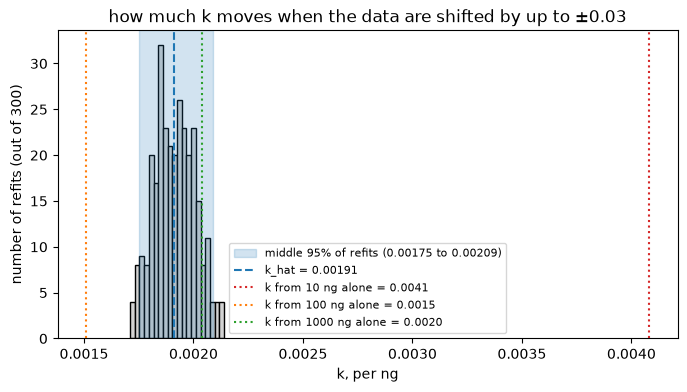

In [130]:
# finds the range that holds the middle 95% of the 300 repeats (cutting out the 15 most extreme ones)
k_sorted = sorted(k_values)
low = k_sorted[int(0.025 * n_repeats)]
high = k_sorted[int(0.975 * n_repeats) - 1]

# the k each dose gives on its own (from the algebra in cell 6)
k_each = [0.0] * len(dose)
for i in range(len(dose)):
    k_each[i] = -math.log(1 - observed_fractions[i]) / dose[i]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(k_values, bins=20, color="lightgray", edgecolor="black")
ax.axvspan(low, high, color="tab:blue", alpha=0.2, label=f"middle 95% of refits ({low:.5f} to {high:.5f})")
ax.axvline(k_hat, color="tab:blue", ls="--", label=f"k_hat = {k_hat:.5f}")
colors = ["tab:red", "tab:orange", "tab:green"]
for i in range(len(dose)):
    ax.axvline(k_each[i], color=colors[i], ls=":", label=f"k from {dose[i]} ng alone = {k_each[i]:.4f}")
ax.set_xlabel("k, per ng")
ax.set_ylabel("number of refits (out of 300)")
ax.set_title("how much k moves when the data are shifted by up to ±0.03")
ax.legend(fontsize=8)
plt.show()